# Low-rank approximation: compress an image with SVD

A grayscale image is a matrix `A`, and each color channel of an image is its own matrix. The singular value decomposition (SVD) expresses a matrix as a sum of simple rank-one matrices. Keeping only the largest `k` terms gives a lower-rank approximation:

$$A \approx A_k = U_k\,\Sigma_k\,V_k^\mathsf{T}.$$

We will explore what **rank** means, use the Eckart–Young theorem to understand why the truncated SVD is the best rank-`k` approximation, and compare several ranks visually.

## 1. Rank-one building blocks

A rank-one matrix is an outer product of one column vector and one row vector. The SVD writes any matrix as a sum of such building blocks, ordered from largest contribution to smallest. The singular values `σ₁ ≥ σ₂ ≥ ⋯ ≥ 0` tell us the strength of each block.

In [1]:
using LinearAlgebra
using Images
using ImageIO

A = [3.0 0.0 0.0;
     0.0 2.0 0.0]
F = svd(A)
(F.U, F.S, F.Vt)

([1.0 0.0; 0.0 1.0], [3.0, 2.0], [1.0 0.0 0.0; 0.0 1.0 0.0])

In [2]:
rank_one_terms = [F.S[i] .* (F.U[:, i] * F.Vt[i, :]') for i in eachindex(F.S)]
(rank_one_terms, sum(rank_one_terms))

([[3.0 0.0 0.0; 0.0 0.0 0.0], [0.0 0.0 0.0; 0.0 2.0 0.0]], [3.0 0.0 0.0; 0.0 2.0 0.0])

Each term has rank at most one, and their sum reconstructs `A`. The numerical rank is the number of nonzero singular values (in computation, values smaller than a tolerance are treated as zero). Keeping fewer terms discards the weaker components.

## 2. The Eckart–Young theorem

For any matrix `A` and any `k`, the truncated SVD `Aₖ` is a best approximation among all matrices of rank at most `k`. More precisely, it minimizes both the Frobenius error and the spectral-norm error:

$$\|A-B\|_F \geq \|A-A_k\|_F = \sqrt{\sum_{i>k}\sigma_i^2}, \qquad \operatorname{rank}(B)\leq k.$$

The spectral-norm error is likewise minimized, with `‖A - Aₖ‖₂ = σₖ₊₁`. We can check the Frobenius formula on the small example.

In [3]:
k = 1
A_k = F.U[:, 1:k] * Diagonal(F.S[1:k]) * F.Vt[1:k, :]
measured_error = norm(A - A_k)
predicted_error = sqrt(sum(abs2, F.S[k+1:end]))
(A_k, measured_error, predicted_error)

([3.0 0.0 0.0; 0.0 0.0 0.0], 2.0, 2.0)

The measured and predicted errors agree up to floating-point rounding. The theorem says more than that truncation works: among **all** rank-one matrices, this SVD truncation has the smallest possible Frobenius error.

## 3. First: grayscale low-rank approximation

Start with a grayscale image, which is a single matrix. Its SVD gives a direct view of how much structure can be captured with just a few rank-one components. We use a reduced image size to keep the computation quick and the factorization easy to explore.

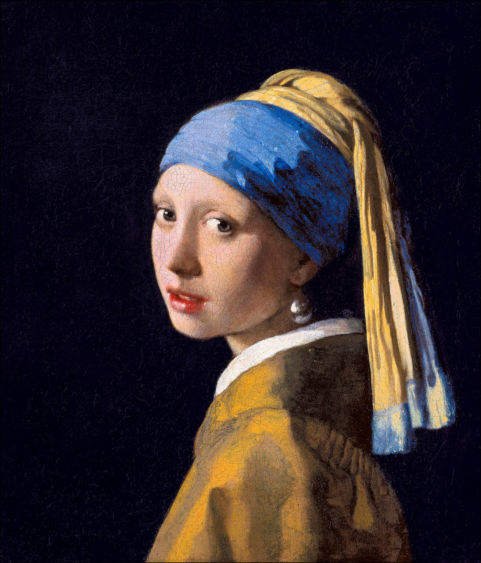

In [4]:
image_path = joinpath(@__DIR__, "..", "images", "girl-with-pearl-earring.jpg")
original = load(image_path)
original

The original color image is shown first. For the grayscale section, we convert a reduced-size copy to one brightness matrix; the later color section will use the three RGB channels.

In [5]:
gray_image = Gray.(original[1:1:end, 1:1:end])
gray_matrix = Float64.(gray_image)
size(gray_matrix)

(2248, 1920)

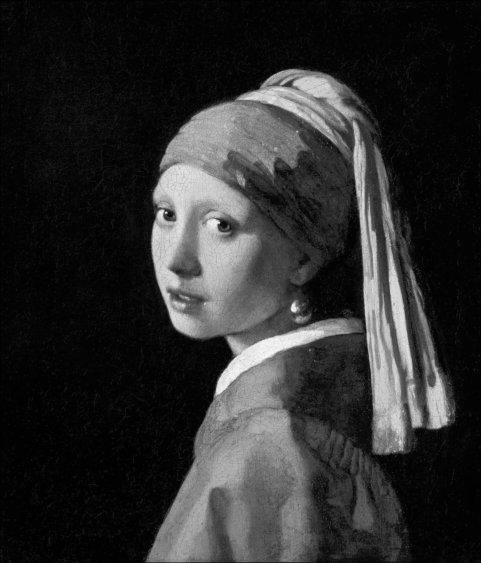

In [6]:
gray_image

In [7]:
gray_svd = svd(gray_matrix)
gray_svd.S[1:12]

12-element Vector{Float64}:
 515.0379791524169
 210.74463572576565
 158.0884762812404
  91.75109064035594
  80.08680704696476
  73.37156029937368
  68.29509969002926
  60.061785697398086
  51.45742566620557
  45.376952770933336
  41.67091007096176
  35.049689730230135

The singular values are listed from largest to smallest. Large early values capture strong, broad patterns; smaller later values capture progressively finer variations. We will use the same set of ranks for the grayscale and color comparisons.

### Compare grayscale reconstructions

Each panel below is generated using the corresponding value in `ranks`, in vector order. Increasing the rank adds detail while also increasing the number of values needed to store the factorization.

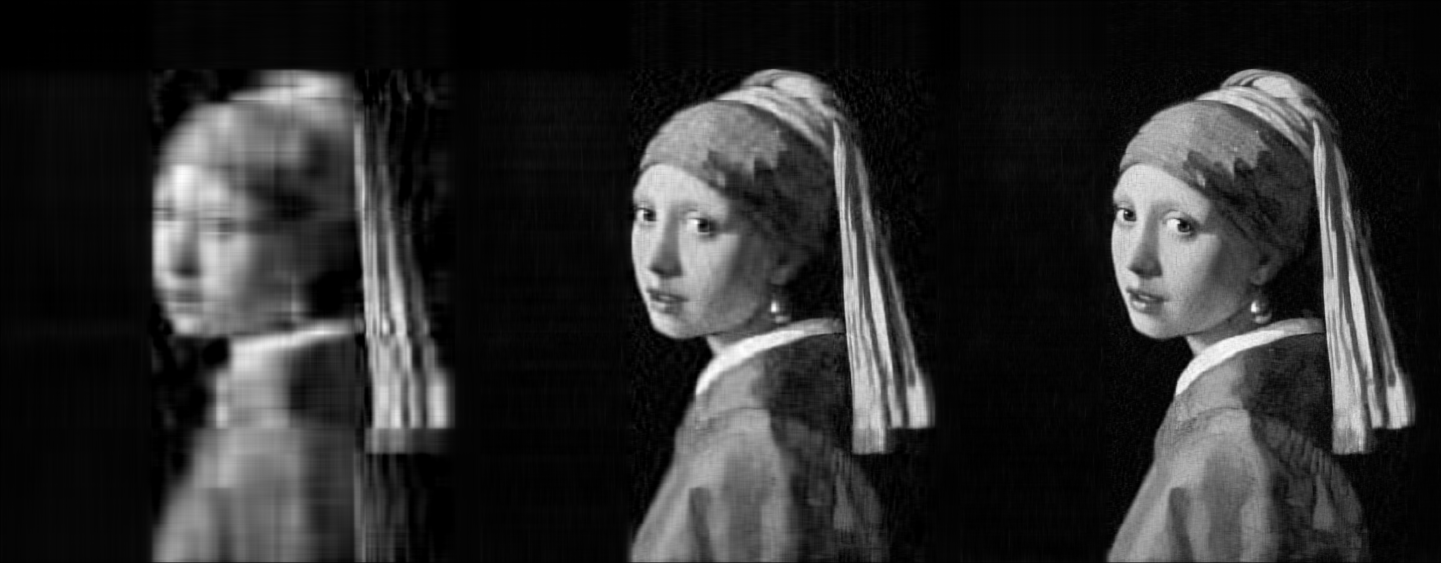

In [8]:
function reconstruct_rank(F, k)
    1 <= k <= length(F.S) || throw(ArgumentError("k must be between 1 and $(length(F.S))"))
    F.U[:, 1:k] * Diagonal(F.S[1:k]) * F.Vt[1:k, :]
end

ranks = [8, 32, 64]
gray_reconstructions = [reconstruct_rank(gray_svd, k) for k in ranks]
Gray.(clamp.(hcat(gray_reconstructions...), 0, 1))

In [9]:
gray_relative_errors = [norm(gray_matrix - R) / norm(gray_matrix) for R in gray_reconstructions]
gray_energy_retained = [sum(abs2, gray_svd.S[1:k]) / sum(abs2, gray_svd.S) for k in ranks]
height, width = size(gray_matrix)
gray_storage_ratios = [k * (height + width + 1) / (height * width) for k in ranks]
[(rank=ranks[i], relative_error=gray_relative_errors[i], energy_retained=gray_energy_retained[i], storage_ratio=gray_storage_ratios[i]) for i in eachindex(ranks)]

3-element Vector{@NamedTuple{rank::Int64, relative_error::Float64, energy_retained::Float64, storage_ratio::Float64}}:
 (rank = 8, relative_error = 0.3189930933454889, energy_retained = 0.8982434063969519, storage_ratio = 0.007727239027283511)
 (rank = 32, relative_error = 0.24374546836325237, energy_retained = 0.9405881466518363, storage_ratio = 0.030908956109134043)
 (rank = 64, relative_error = 0.22558508483436637, energy_retained = 0.9491113694998051, storage_ratio = 0.06181791221826809)

The Frobenius relative error decreases as rank increases, and the retained energy increases. The storage ratio compares the number of values in the factorization (`k` left-vector values, `k` right-vector values, and `k` singular values) with the number of grayscale pixels. Ratios below 1 indicate fewer stored values, before metadata and precision are considered.

## 4. Next: color low-rank approximation

A color image has red, green, and blue values at every pixel. A straightforward extension is to treat each color channel as its own matrix, compute an SVD for each one, and reconstruct all three with the same rank. This is easy to understand and lets us compare directly with the grayscale approximation.

In [10]:
color_image = RGB.(original[1:4:end, 1:4:end])
channel_matrices = Float64.(channelview(color_image))
size(channel_matrices)

(3, 562, 480)

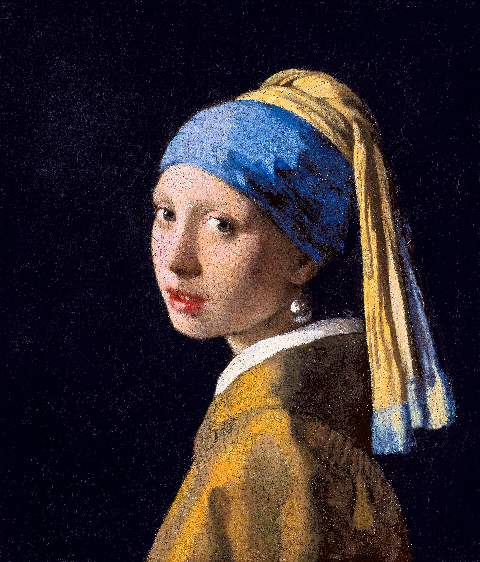

In [11]:
color_image

In [12]:
channel_svds = [svd(channel_matrices[channel, :, :]) for channel in 1:3]
[(channel=channel, leading_singular_values=channel_svds[channel].S[1:12]) for channel in 1:3]

3-element Vector{@NamedTuple{channel::Int64, leading_singular_values::Vector{Float64}}}:
 (channel = 1, leading_singular_values = [151.09943396911683, 62.622508879283785, 44.789785488768494, 27.70558644117604, 24.132269024041502, 20.55269106780662, 19.477154023382393, 17.34694885736425, 15.143818578330889, 13.846318455525706, 12.399972297129995, 10.373886072907197])
 (channel = 2, leading_singular_values = [122.67717694072469, 51.82383796633411, 39.86248957123714, 23.013026455617297, 19.708643554001327, 18.599752739895685, 16.983582327526012, 15.136720527749649, 12.876159620336475, 11.54756572938421, 10.58816399723357, 9.315178169753747])
 (channel = 3, leading_singular_values = [115.81482331245994, 38.46699322111352, 32.40265946531627, 20.444701685313667, 16.651256262903626, 14.857745556555905, 14.626940567078234, 12.655969639045251, 11.266543673616788, 10.369822983505905, 9.401262076305215, 8.792548327115929])

Each channel has its own singular-value spectrum. In the reconstruction below, the same rank is kept for red, green, and blue; their reconstructed matrices are then combined into a color image.

### Compare color reconstructions

Each panel uses the corresponding value in `ranks`, in vector order. Values are clamped to `[0, 1]` for display.

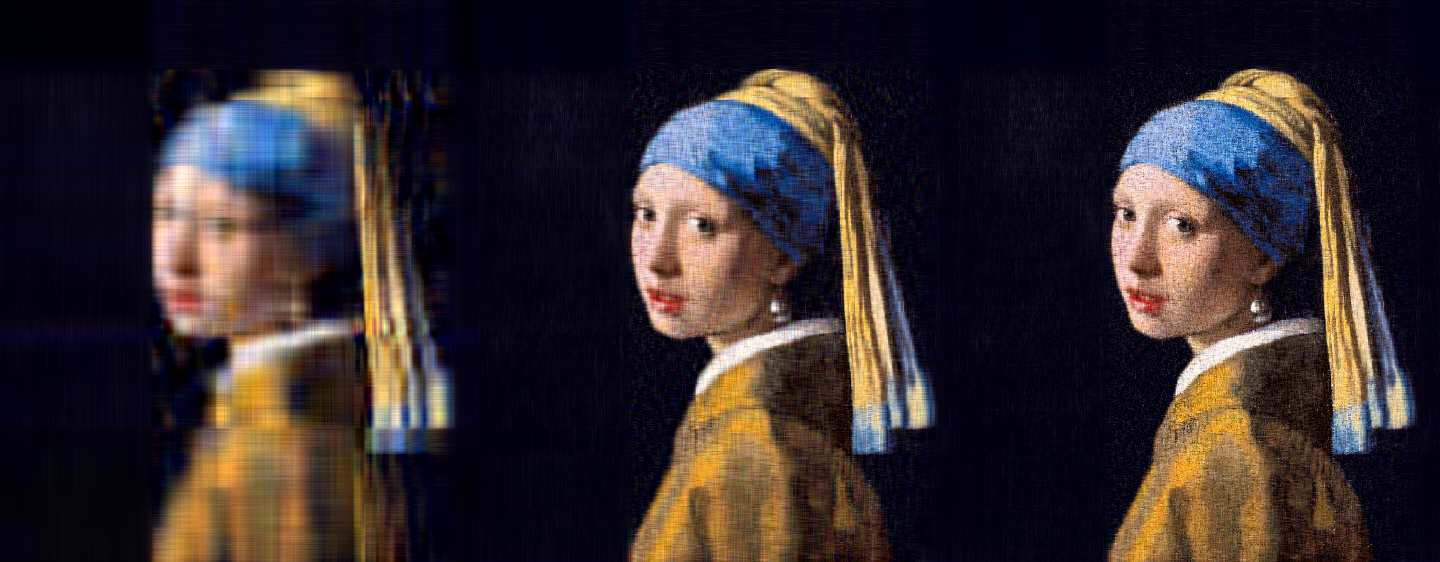

In [13]:
function reconstruct_color_rank(channel_svds, k)
    channel_stack = cat((reconstruct_rank(F, k) for F in channel_svds)...; dims=3)
    colorview(RGB, permutedims(clamp.(channel_stack, 0, 1), (3, 1, 2)))
end

color_reconstructions = [reconstruct_color_rank(channel_svds, k) for k in ranks]
colorview(RGB, cat((Float64.(channelview(image)) for image in color_reconstructions)...; dims=3))

In [14]:
color_relative_errors = [sqrt(sum(norm(channel_matrices[c, :, :] - reconstruct_rank(channel_svds[c], k))^2 for c in 1:3)) / norm(channel_matrices) for k in ranks]
color_energy_retained = [sum(sum(abs2, F.S[1:k]) for F in channel_svds) / sum(sum(abs2, F.S) for F in channel_svds) for k in ranks]
height, width = size(color_image)
color_storage_ratios = [3 * k * (height + width + 1) / (3 * height * width) for k in ranks]
[(rank=ranks[i], relative_error=color_relative_errors[i], energy_retained=color_energy_retained[i], storage_ratio=color_storage_ratios[i]) for i in eachindex(ranks)]

3-element Vector{@NamedTuple{rank::Int64, relative_error::Float64, energy_retained::Float64, storage_ratio::Float64}}:
 (rank = 8, relative_error = 0.31783346985499883, energy_retained = 0.8989818854400139, storage_ratio = 0.030931198102016607)
 (rank = 32, relative_error = 0.22912122722844672, energy_retained = 0.947503463233373, storage_ratio = 0.12372479240806643)
 (rank = 64, relative_error = 0.19048944731038242, energy_retained = 0.9637137704634136, storage_ratio = 0.24744958481613286)

The color metrics combine squared errors or energy across all three channels. The storage ratio is the same as for grayscale when each channel has the same height and width and uses the same rank: both the factor storage and raw pixel count are tripled. Applying truncated SVD independently to all three channels minimizes their combined squared error when each channel is restricted to rank at most `k`.

Low-rank approximation is optimal for the chosen matrix error measure, but perceptual quality is not the same as Frobenius error. Fine details or color shifts may matter to a viewer even when they contribute little total squared error. More advanced color compression can transform color spaces or allocate different ranks to different channels.

## Your turn

1. Compare the grayscale and color panels at the same rank. Which details are easier to recognize in color?
2. Add another rank to `ranks` and compare the visual change with the change in each error metric.
3. How many singular components are needed before the storage ratio reaches 1? Is the image visually convincing at that rank?
4. Try the same experiment with another image in the `images/` folder. Which image seems to have a faster-decaying singular-value spectrum?

The Eckart–Young theorem guarantees minimum Frobenius error for the truncated SVD, not necessarily the most perceptually pleasing reconstruction.